<a href="https://colab.research.google.com/github/satyapal2240/satya/blob/main/21_11_26_hindi_cogtrans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CogTrans-Hindi: Emotion-Aware Sentiment Analysis for Hindi

> **Paper:** *CogTrans for Hindi: LLM-Infused Emotion-Aware Sentiment Analysis in a Low-Resource Indian Language Setting*  
## Important: Why low accuracy on demo data?
Without a real CSV, the notebook generates **100 synthetic samples** (140 train).  
MuRIL (~237M parameters) **cannot learn** from 140 samples — accuracy ~33–40% is expected (random baseline).  
**Supply `hindi_data.csv` with ≥ 1,000 real labeled samples** to reproduce paper results.


## Section 1 — Environment Setup

In [1]:
# ═══════════════════════════════════════════════════════════════════
# Section 1 — Environment Setup
# ═══════════════════════════════════════════════════════════════════
# IMPORTANT — Read before running:
#   1. Run THIS cell only
#   2. Then go to: Runtime → Restart session
#   3. Then run ALL remaining cells (skip this one)
# ───────────────────────────────────────────────────────────────────
# Why restart? Colab already has numpy/scipy/transformers/sklearn.
# Installing extra packages in the same session can corrupt the
# import cache. A fresh restart loads everything cleanly.
# ═══════════════════════════════════════════════════════════════════

import subprocess, sys

def pip_install(pkg):
    """Install only if not already present. Never touch numpy/scipy."""
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", "--no-deps", pkg],
        capture_output=True, text=True
    )
    if result.returncode == 0:
        print(f"  ✓ {pkg}")
    else:
        print(f"  ✗ {pkg}")
        print(f"    {result.stderr.strip()[:120]}")

# ── Only install packages NOT already in Colab ─────────────────────
# DO NOT install numpy, scipy, scikit-learn, torch, transformers —
# Colab already has correct compatible versions of all of these.
MISSING_PKGS = [
    "sentencepiece",       # needed by MuRIL tokenizer
    "sacremoses",          # needed by some tokenizers
    "indic-nlp-library",   # Hindi/Indic text normalization
]

print("Installing missing packages (sentencepiece, sacremoses, indic-nlp-library)...")
for pkg in MISSING_PKGS:
    pip_install(pkg)

print()
print("✓ Done.")
print()
print("═" * 55)
print("  NEXT STEP: Runtime → Restart session")
print("  Then run all cells from Section 2 onwards.")
print("  Do NOT re-run this cell after restarting.")
print("═" * 55)


Installing missing packages (sentencepiece, sacremoses, indic-nlp-library)...
  ✓ sentencepiece
  ✓ sacremoses
  ✓ indic-nlp-library

✓ Done.

═══════════════════════════════════════════════════════
  NEXT STEP: Runtime → Restart session
  Then run all cells from Section 2 onwards.
  Do NOT re-run this cell after restarting.
═══════════════════════════════════════════════════════


In [1]:
# ═══════════════════════════════════════════════════════════════════
# Run this AFTER restarting runtime (after Section 1 install cell)
# ═══════════════════════════════════════════════════════════════════
import os, re, random, warnings
import unicodedata
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score,
    recall_score, classification_report, confusion_matrix
)
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

# ── Reproducibility ───────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

DEVICE   = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BACKBONE = "google/muril-base-cased"
MAX_LEN  = 128
BATCH    = 16
EPOCHS   = 15
LR       = 1e-5

LABEL_MAP = {"Positive": 0, "Negative": 1, "Neutral": 2}
INV_LABEL = {v: k for k, v in LABEL_MAP.items()}

import transformers, sklearn
print(f"numpy        : {np.__version__}")
print(f"torch        : {torch.__version__}")
print(f"transformers : {transformers.__version__}")
print(f"sklearn      : {sklearn.__version__}")
print(f"Device       : {DEVICE}")
if not torch.cuda.is_available():
    print()
    print(" No GPU. Training will be slow (~hours on real data).")
    print("   Runtime → Change runtime type → T4 GPU  (free)")
else:
    print(f"GPU          : {torch.cuda.get_device_name(0)}")
print("\n✓ All imports successful.")


numpy        : 2.4.6
torch        : 2.14.1+cu130
transformers : 5.22.1
sklearn      : 1.6.1
Device       : cuda
GPU          : Tesla T4

✓ All imports successful.


## Section 2 — Data Loading

In [2]:
# ═══════════════════════════════════════════════════════════════════
# Section 2 — Load hi-train, hi-valid, hi-test
# Supports: with header OR without header (label in col-0, text in col-1)
# ═══════════════════════════════════════════════════════════════════

from google.colab import files as colab_files
import io, os
import pandas as pd

LABEL_MAP = {'Positive': 0, 'Negative': 1, 'Neutral': 2}
INV_LABEL = {v: k for k, v in LABEL_MAP.items()}

# Label synonyms — covers numeric AND string variants
LABEL_SYNONYMS = {
    # English strings
    'positive': 'Positive', 'negative': 'Negative', 'neutral': 'Neutral',
    'pos':      'Positive', 'neg':      'Negative', 'neu':     'Neutral',
    # Numeric (0/1/2)
    '0': 'Positive', '1': 'Negative', '2': 'Neutral',
    # Numeric (1/2/3)
    '1': 'Positive', '2': 'Negative', '3': 'Neutral',
}

print('Upload your 3 CSV files: hi-train, hi-valid, hi-test')
print('Hold Ctrl (Windows) or Cmd (Mac) to select all 3 at once.')
uploaded = colab_files.upload()
print(f'\nReceived {len(uploaded)} file(s): {list(uploaded.keys())}')

def find_split(uploaded_dict, keyword):
    for fname, data in uploaded_dict.items():
        if keyword.lower() in fname.lower():
            return fname, data
    raise FileNotFoundError(
        f'No file with "{keyword}" found.\nUploaded: {list(uploaded_dict.keys())}')

def normalise_label(val):
    """Map any label variant to Positive/Negative/Neutral."""
    return LABEL_SYNONYMS.get(str(val).strip().lower(), str(val).strip().capitalize())

def read_csv_split(fname, data, split_name):
    """Read bytes → clean DataFrame. Auto-detects missing header."""
    sample = data[:4096].decode('utf-8', errors='ignore')
    sep    = '\t' if '\t' in sample.split('\n')[0] else ','

    # Peek at first row to detect if file has a header
    df_peek = pd.read_csv(io.BytesIO(data), sep=sep, encoding='utf-8',
                          on_bad_lines='skip', nrows=2)
    first_col = str(df_peek.columns[0]).strip().lower()

    if first_col in LABEL_SYNONYMS:
        # No header: col-0 = label, col-1 = text
        print(f'  [{split_name}] No header → col-0=label, col-1=text')
        df = pd.read_csv(io.BytesIO(data), sep=sep, encoding='utf-8',
                         header=None, on_bad_lines='skip')
        df.rename(columns={0: 'label', 1: 'text'}, inplace=True)
    else:
        # Has header: normalise column names
        df = pd.read_csv(io.BytesIO(data), sep=sep, encoding='utf-8',
                         on_bad_lines='skip')
        df.columns = df.columns.str.strip().str.lower()
        for alt in ['sentence','review','content','hindi','input','text_a']:
            if alt in df.columns and 'text' not in df.columns:
                df.rename(columns={alt: 'text'}, inplace=True)
        for alt in ['sentiment','class','category','polarity','output','target']:
            if alt in df.columns and 'label' not in df.columns:
                df.rename(columns={alt: 'label'}, inplace=True)

    if 'text' not in df.columns or 'label' not in df.columns:
        raise ValueError(
            f'[{split_name}] Cannot find text/label columns.\n'
            f'Columns found: {list(df.columns)}')

    if 'emotion' not in df.columns:
        df['emotion'] = 'unknown'

    df = df.dropna(subset=['text','label'])
    df['text']  = df['text'].astype(str).str.strip()
    df['label'] = df['label'].apply(normalise_label)
    df = df[df['label'].isin(LABEL_MAP)].reset_index(drop=True)
    df['label_id'] = df['label'].map(LABEL_MAP)

    dist = '  '.join(f'{k}:{v}' for k,v in df['label'].value_counts().items())
    print(f'  [{split_name:5s}] {len(df):>6,} samples  |  {dist}')
    return df

# ── Load each split ────────────────────────────────────────────────────
print('\nLoading splits...')
fname_tr, data_tr = find_split(uploaded, 'train')
fname_vl, data_vl = find_split(uploaded, 'valid')
fname_te, data_te = find_split(uploaded, 'test')

df_train = read_csv_split(fname_tr, data_tr, 'TRAIN')
df_valid  = read_csv_split(fname_vl, data_vl, 'VALID')
df_test   = read_csv_split(fname_te, data_te, 'TEST')

print(f'\n✓ All splits loaded.')
print(f'  Train : {len(df_train):>6,} samples')
print(f'  Valid : {len(df_valid):>6,} samples')
print(f'  Test  : {len(df_test):>6,} samples')
print(f'  Total : {len(df_train)+len(df_valid)+len(df_test):>6,} samples')
print('\nSample rows (train):')
df_train[['text','label']].head(5)


Upload your 3 CSV files: hi-train, hi-valid, hi-test
Hold Ctrl (Windows) or Cmd (Mac) to select all 3 at once.


Saving hi-test.csv to hi-test.csv
Saving hi-train.csv to hi-train.csv
Saving hi-valid.csv to hi-valid.csv

Received 3 file(s): ['hi-test.csv', 'hi-train.csv', 'hi-valid.csv']

Loading splits...
  [TRAIN] No header → col-0=label, col-1=text
  [TRAIN]  2,480 samples  |  Positive:1042  Negative:741  Neutral:697
  [VALID] No header → col-0=label, col-1=text
  [VALID]    310 samples  |  Positive:121  Negative:109  Neutral:80
  [TEST] No header → col-0=label, col-1=text
  [TEST ]    310 samples  |  Positive:122  Negative:98  Neutral:90

✓ All splits loaded.
  Train :  2,480 samples
  Valid :    310 samples
  Test  :    310 samples
  Total :  3,100 samples

Sample rows (train):


,text,label
0,"निर्माता :\nशीतल विनोद तलवार, मधु‍ मैंटेना\n\n...",Neutral
1,’उड़ान’ से विक्रमादित्य\nमोटवाने\nने अच्छे सिन...,Positive
2,फिल्म में गानों के दृश्य में अनुष्का को माइक क...,Neutral
3,फांसी चढ़ने से पहले वह पाकिस्तान के सदर से खास...,Neutral
4,राज कुमार हिरानी ने इस मूवी में भी अपने डायरेक...,Positive


## Section 3 — Hindi Preprocessing

In [3]:
# ── Hindi stop words (IndicNLP-based) ─────────────────────────────────
# FIX: corrected syntax error from previous version ('नहीं'हीं was broken)
HINDI_STOPWORDS = {
    'है', 'हैं', 'का', 'की', 'के', 'में', 'से', 'को', 'पर', 'और',
    'एक', 'यह', 'वह', 'इस', 'उस', 'था', 'थी', 'थे', 'हो', 'हुआ',
    'हुई', 'हुए', 'कि', 'जो', 'तो', 'भी', 'ही', 'नहीं', 'तक',
    'जब', 'फिर', 'अब', 'यहाँ', 'वहाँ', 'इसे', 'उसे', 'इसका',
    'उसका', 'इनका', 'उनका', 'मैं', 'तुम', 'आप', 'हम', 'वे', 'ये',
    'कोई', 'कुछ', 'सब', 'सभी', 'बहुत', 'बिल्कुल', 'काफी', 'थोड़ा',
    'बस', 'तथा', 'व', 'एवं', 'या', 'अथवा', 'लेकिन', 'परन्तु', 'किन्तु'
}

def detect_codemix(token):
    """True if token is likely English (pure ASCII letters)."""
    return bool(re.match(r'^[a-zA-Z]+$', token))

def preprocess_hindi(text):
    if not isinstance(text, str) or not text.strip():
        return ''
    # 1. Unicode NFC — normalises Devanagari matras/conjuncts
    text = unicodedata.normalize('NFC', text)
    # 2. Lowercase
    text = text.lower()
    # 3. URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)
    # 4. Mentions
    text = re.sub(r'@\w+', '@USER', text)
    # 5. Hashtags — keep word
    text = re.sub(r'#(\w+)', r'\1', text)
    # 6. Emoji → token
    text = re.sub(
        r'[\U0001F600-\U0001F64F\U0001F300-\U0001F5FF'
        r'\U0001F680-\U0001F6FF\U0001F1E0-\U0001F1FF'
        r'\u2600-\u26FF\u2700-\u27BF]',
        ' EMOJI ', text)
    # 7. Keep only Devanagari, ASCII alnum, spaces
    text = re.sub(r'[^\w\s\u0900-\u097F]', ' ', text)
    # 8. Collapse whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    # 9. Stop word removal + code-mix tagging
    result = []
    for t in text.split():
        if t in HINDI_STOPWORDS:
            continue
        result.append('CODEMIX_EN' if detect_codemix(t) else t)
    return ' '.join(result)

# ── Apply to all three splits ────────────────────────────────────
for _name, _df in [('TRAIN', df_train), ('VALID', df_valid), ('TEST', df_test)]:
    _df['text_clean'] = _df['text'].apply(preprocess_hindi)
    _df['label_id']   = _df['label'].map(LABEL_MAP)
    _empty = (_df['text_clean'].str.strip() == '').sum()
    if _empty: print(f'  [{_name}] {_empty} rows empty after preprocessing — dropping.')
    print(f'  [{_name}] preprocessing done.')


# Show before/after sample (train)
print('Preprocessing — Before vs After (train sample):')
print('-' * 70)
for _, row in df_train[['text','text_clean']].head(4).iterrows():
    print(f'  Original : {row["text"]}')
    print(f'  Cleaned  : {row["text_clean"]}')
    print()

  [TRAIN] preprocessing done.
  [VALID] preprocessing done.
  [TEST] preprocessing done.
Preprocessing — Before vs After (train sample):
----------------------------------------------------------------------
  Original : निर्माता :
शीतल विनोद तलवार, मधु‍ मैंटेना

निर्देशक :
रामगोपाल वर्मा

कलाकार :
विवेक ओबेरॉय, शत्रुघ्न सिन्हा, अभिमन्यु सिंह, सुशांत सिंह, जरीन वहाब, आशीष विद्यार्थी, राजा कृष्णमूर्ति, श्रीनिवास राव

* केवल वयस्कों के लिए * 16 रील * 2 घंटे 14 मिनट


’रक्तचरित्र-1’ शुरू होते ही स्पष्टीकरण ‍लिखा हुआ आता है कि सारे पात्र और कहानी काल्पिनक हैं। अगले ही ‍पल दिखाई देता है कि फिल्म एक सच्ची कहानी पर आधारित है। शायद कानूनी उलझनों से बचने के लिए रामगोपाल वर्मा को विरोधाभास बातें साथ करनी पड़ी हो।

‘रक्तचरित्र’ की कहानी आंध्रप्रदेश के रवि परिताला और उसके विरोधी सूरी पर आधारित है। रामू ने उससे प्रेरणा लेकर, कुछ अपनी कल्पना मिलाकर ‘रक्तचरित्र’ को दो भागों में बनाया है।

पहले भाग में दिखाया गया है कि किस तरह अपने पिता और भाई की हत्या होने के बाद रवि (फिल्म में प्रताप) अपना बदला लेता

## Section 4 — QAM: Quantity Augmentation Module

In [4]:
# ── QAM configuration ──────────────────────────────────────────────────
# N_AUG: augmented copies per training sample
# Use N_AUG=2 for small datasets (<2000), N_AUG=1 for larger ones
N_AUG = 2 if len(df_train) < 2000 else 1
print(f'QAM: N_AUG={N_AUG} (train size={len(df_train)})')

# ── Hindi synonym/antonym dictionaries ─────────────────────────────────
HINDI_SYNONYMS = {
    'अच्छा': 'बेहतरीन', 'बेहतरीन': 'शानदार', 'शानदार': 'उत्कृष्ट',
    'खुशी': 'प्रसन्नता', 'प्रसन्नता': 'हर्ष',
    'बुरा': 'खराब', 'खराब': 'निकृष्ट',
    'दुख': 'पीड़ा', 'पीड़ा': 'वेदना',
    'गुस्सा': 'क्रोध', 'क्रोध': 'रोष',
    'प्यार': 'स्नेह', 'स्नेह': 'प्रेम',
    'डर': 'भय', 'भय': 'आतंक',
    'सुंदर': 'खूबसूरत', 'खूबसूरत': 'मनोहर',
    'बेकार': 'निकम्मा', 'निकम्मा': 'व्यर्थ',
    'मुश्किल': 'कठिन', 'कठिन': 'दुष्कर',
    'आसान': 'सरल', 'सरल': 'सहज',
    'काम': 'कार्य', 'सेवा': 'सहायता',
}
HINDI_ANTONYMS = {
    'अच्छा': 'बुरा', 'बुरा': 'अच्छा',
    'खुशी': 'दुख', 'दुख': 'खुशी',
    'प्यार': 'नफरत', 'नफरत': 'प्यार',
    'बेहतरीन': 'बेकार', 'बेकार': 'बेहतरीन',
    'शानदार': 'घटिया', 'घटिया': 'शानदार',
    'सुंदर': 'बदसूरत', 'बदसूरत': 'सुंदर',
    'सफल': 'असफल', 'असफल': 'सफल',
    'मजबूत': 'कमजोर', 'कमजोर': 'मजबूत',
    'सही': 'गलत', 'गलत': 'सही',
    'आसान': 'मुश्किल', 'मुश्किल': 'आसान',
}

def augment_synonym(text):
    """TG-Prompt1: Replace with semantically similar Hindi words."""
    return ' '.join([HINDI_SYNONYMS.get(t, t) for t in text.split()])

def augment_antonym(text):
    """TG-Prompt2: Replace with antonyms (changes local sentiment polarity)."""
    return ' '.join([HINDI_ANTONYMS.get(t, t) for t in text.split()])

def augment_deletion(text, drop_prob=0.15):
    """TG-Prompt3 fallback: random token deletion."""
    tokens = text.split()
    if len(tokens) <= 3: return text
    return ' '.join([t for t in tokens if random.random() > drop_prob]) or text

def length_ratio_ok(orig, aug, threshold=0.5):
    """Reject augmented samples that are too short vs original."""
    if not aug.strip(): return False
    lo, la = len(orig.split()), len(aug.split())
    return min(lo, la) / max(lo, la, 1) >= threshold

def run_qam(df, n_aug=N_AUG):
    strategies = [augment_synonym, augment_antonym, augment_deletion]
    aug_rows, rejected = [], 0
    for _, row in df.iterrows():
        for i in range(n_aug):
            fn  = strategies[i % len(strategies)]
            aug = fn(row['text_clean'])
            if not length_ratio_ok(row['text_clean'], aug):
                rejected += 1
                continue
            aug_rows.append({
                'text': aug, 'text_clean': aug,
                'label': row['label'], 'label_id': row['label_id'],
                'emotion': row.get('emotion', 'unknown'),
                'augmented': True
            })
    orig_df = df.copy()
    orig_df['augmented'] = False
    combined = pd.concat([orig_df, pd.DataFrame(aug_rows)], ignore_index=True)
    print(f'QAM: {len(df)} → {len(combined)} samples  '
          f'(+{len(aug_rows)} augmented, {rejected} rejected)')
    return combined

# QAM augments only TRAIN split — valid and test stay clean
df_aug = run_qam(df_train)
print('\nAugmented train distribution:')
print(df_aug['label'].value_counts().to_string())

QAM: N_AUG=1 (train size=2480)
QAM: 2480 → 4960 samples  (+2480 augmented, 0 rejected)

Augmented train distribution:
label
Positive    2084
Negative    1482
Neutral     1394


## Section 5 — ECA: Hindi OCC Emotion Cognitive Analysis

In [5]:
# ── Hindi OCC Emotion Lexicon ─────────────────────────────────────────
# Source: Hindi SentiWordNet (Balamurali et al., 2012) + manual extension
# Format: word → (OCC_dimension, PECI/NECI)
HINDI_OCC_LEXICON = {
    # PECI — Positive Emotion Cognitive Integration
    'खुशी':       ('Desirable',    'PECI'),
    'प्रसन्नता':  ('Desirable',    'PECI'),
    'हर्ष':       ('Desirable',    'PECI'),
    'राहत':       ('Desirable',    'PECI'),
    'संतोष':      ('Desirable',    'PECI'),
    'प्यार':      ('Desirable',    'PECI'),
    'स्नेह':      ('Desirable',    'PECI'),
    'प्रेम':      ('Desirable',    'PECI'),
    'आभार':       ('Desirable',    'PECI'),
    'धन्यवाद':    ('Desirable',    'PECI'),
    'प्रशंसा':    ('Praiseworthy', 'PECI'),
    'सम्मान':     ('Praiseworthy', 'PECI'),
    'अच्छा':      ('Praiseworthy', 'PECI'),
    'बेहतरीन':    ('Praiseworthy', 'PECI'),
    'शानदार':     ('Praiseworthy', 'PECI'),
    'उत्कृष्ट':   ('Praiseworthy', 'PECI'),
    'सफल':        ('Praiseworthy', 'PECI'),
    'साहसी':      ('Praiseworthy', 'PECI'),
    'उम्मीद':     ('Desirable',    'PECI'),
    'आशा':        ('Desirable',    'PECI'),
    'विश्वास':    ('Confirmed',    'PECI'),
    'मनोहर':      ('Praiseworthy', 'PECI'),
    'खूबसूरत':    ('Praiseworthy', 'PECI'),
    'प्रशंसनीय':  ('Praiseworthy', 'PECI'),
    'सहायक':      ('Praiseworthy', 'PECI'),
    # NECI — Negative Emotion Cognitive Integration
    'दुख':        ('Undesirable',  'NECI'),
    'पीड़ा':       ('Undesirable',  'NECI'),
    'वेदना':      ('Undesirable',  'NECI'),
    'निराशा':     ('Undesirable',  'NECI'),
    'दर्द':       ('Undesirable',  'NECI'),
    'गुस्सा':     ('Blameworthy',  'NECI'),
    'क्रोध':      ('Blameworthy',  'NECI'),
    'रोष':        ('Blameworthy',  'NECI'),
    'नफरत':       ('Blameworthy',  'NECI'),
    'घृणा':       ('Blameworthy',  'NECI'),
    'डर':         ('Undesirable',  'NECI'),
    'भय':         ('Undesirable',  'NECI'),
    'आतंक':       ('Undesirable',  'NECI'),
    'चिंता':      ('Undesirable',  'NECI'),
    'बुरा':       ('Blameworthy',  'NECI'),
    'खराब':       ('Blameworthy',  'NECI'),
    'निकृष्ट':    ('Blameworthy',  'NECI'),
    'बेकार':      ('Blameworthy',  'NECI'),
    'निकम्मा':    ('Blameworthy',  'NECI'),
    'व्यर्थ':     ('Blameworthy',  'NECI'),
    'असफल':       ('Blameworthy',  'NECI'),
    'खतरा':       ('Undesirable',  'NECI'),
    'शर्म':       ('Blameworthy',  'NECI'),
    'पछतावा':     ('Disconfirmed', 'NECI'),
    'परेशान':     ('Undesirable',  'NECI'),
    'तकलीफ':      ('Undesirable',  'NECI'),
    'नुकसान':     ('Undesirable',  'NECI'),
    'गलत':        ('Blameworthy',  'NECI'),
}

def extract_eca(text):
    """Extract PECI/NECI features and emotion score from Hindi text."""
    tokens  = str(text).split()
    peci, neci, triggered = 0, 0, []
    for token in tokens:
        if token in HINDI_OCC_LEXICON:
            dim, pol = HINDI_OCC_LEXICON[token]
            triggered.append((token, dim, pol))
            if pol == 'PECI': peci += 1
            else:              neci += 1
    total = peci + neci
    es    = (peci - neci) / total if total > 0 else 0.0
    dom   = 'PECI' if es > 0 else ('NECI' if es < 0 else 'NEUTRAL')
    return {'peci': peci, 'neci': neci, 'emotion_score': round(es, 3),
            'dominant': dom, 'triggered': triggered}

def apply_eca(df):
    """Apply ECA to a dataframe and add columns in-place. Returns df."""
    out = df['text_clean'].apply(extract_eca)
    df = df.copy()
    df['peci']          = out.apply(lambda x: x['peci'])
    df['neci']          = out.apply(lambda x: x['neci'])
    df['emotion_score'] = out.apply(lambda x: x['emotion_score'])
    df['eca_dominant']  = out.apply(lambda x: x['dominant'])
    return df

# Apply ECA to all splits (do NOT recalculate later)
df_aug  = apply_eca(df_aug)
df_valid = apply_eca(df_valid)
df_test  = apply_eca(df_test)

print('ECA complete.')
print('ECA dominant distribution:')
print(df_aug['eca_dominant'].value_counts().to_string())
print('\nSample ECA output (original samples only):')
sample = df_aug[df_aug['augmented'] == False].head(6)
for _, row in sample[['text_clean','peci','neci','emotion_score','eca_dominant']].iterrows():
    print(f'  [{row["eca_dominant"]:7s} ES={row["emotion_score"]:+.2f}] {row["text_clean"][:55]}')

ECA complete.
ECA dominant distribution:
eca_dominant
NEUTRAL    3381
PECI       1382
NECI        197

Sample ECA output (original samples only):
  [NEUTRAL ES=+0.00] निर्माता शीतल विनोद तलवार मधु मैंटेना निर्देशक रामगोपाल
  [PECI    ES=+0.88] उड़ान विक्रमादित्य मोटवाने ने अच्छे सिनेमा उम्मीद जगाई 
  [NEUTRAL ES=+0.00] फिल्म गानों दृश्य अनुष्का माइक सामने लक दक कॉस्ट़्यूम ख
  [NEUTRAL ES=+0.00] फांसी चढ़ने पहले पाकिस्तान सदर खास इजाजत लेकर मीडिया मु
  [PECI    ES=+1.00] राज कुमार हिरानी ने मूवी अपने डायरेक्शन जलवा दिखा दिया।
  [NEUTRAL ES=+0.00] इन फुकरों पहले मिल चुके आपने इन्हें पंसद किया। यही फुकर


In [ ]:
# This cell is redundant as baseline_results are saved and printed in cell t0ny7jqn8Hdp.

In [14]:
# ═══════════════════════════════════════════════════════════════════
# BASELINE TRAINING — mBERT, IndicBERT, XLM-R, MuRIL
# 5 epochs each | Auto-saves to Drive after each model | Skips completed ones
# ═══════════════════════════════════════════════════════════════════

import json, os, torch, gc
import torch.nn as nn
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from tqdm.auto import tqdm

# Force free up GPU memory before starting baseline training
gc.collect()
torch.cuda.empty_cache()

BASELINE_EPOCHS = 5
BASELINE_LR     = 2e-5
BASELINE_BATCH  = 16
BASELINE_MAXLEN = 128
BASELINE_SAVE   = '/content/drive/MyDrive/baseline_results.json'

BASELINES = {
    'mBERT':     'bert-base-multilingual-cased',
    'IndicBERT': 'ai4bharat/indic-bert',
    'XLM-R':     'xlm-roberta-base',
    'MuRIL':     'google/muril-base-cased',
}

# Load existing results if GPU cut off previously
if os.path.exists(BASELINE_SAVE):
    baseline_results = json.load(open(BASELINE_SAVE))
    print(f'✓ Resuming — already done: {list(baseline_results.keys())}')
else:
    baseline_results = {}
    print('Starting fresh baseline run.')

class _DS(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts, self.labels = texts, labels
        self.tokenizer, self.max_len = tokenizer, max_len
    def __len__(self): return len(self.texts)
    def __getitem__(self, i):
        enc = self.tokenizer(str(self.texts[i]), max_length=self.max_len,
                             padding='max_length', truncation=True,
                             return_tensors='pt')
        return {'input_ids':      enc['input_ids'].squeeze(),
                'attention_mask': enc['attention_mask'].squeeze(),
                'label':          torch.tensor(self.labels[i], dtype=torch.long)}

def train_baseline(name, model_name):
    # Aggressively clear cache before loading a new model to avoid CUDA OOM
    gc.collect()
    torch.cuda.empty_cache()

    print(f'\n{"═"*60}')
    print(f'  {name}  ({model_name})')
    print(f'{"═"*60}')

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model     = AutoModelForSequenceClassification.from_pretrained(
                    model_name, num_labels=3,
                    ignore_mismatched_sizes=True).to(DEVICE)

    tr_dl = DataLoader(_DS(df_aug['text_clean'].tolist(),
                           df_aug['label_id'].tolist(),
                           tokenizer, BASELINE_MAXLEN),
                       batch_size=BASELINE_BATCH, shuffle=True, num_workers=0, pin_memory=True)
    vl_dl = DataLoader(_DS(df_valid['text_clean'].tolist(),
                           df_valid['label_id'].tolist(),
                           tokenizer, BASELINE_MAXLEN),
                       batch_size=BASELINE_BATCH, shuffle=False, num_workers=0, pin_memory=True)
    te_dl = DataLoader(_DS(df_test['text_clean'].tolist(),
                           df_test['label_id'].tolist(),
                           tokenizer, BASELINE_MAXLEN),
                       batch_size=BASELINE_BATCH, shuffle=False, num_workers=0, pin_memory=True)

    # Calculate class weights for imbalanced datasets
    class_counts = df_aug['label_id'].value_counts(sort=False).sort_index()
    class_weights = 1.0 / class_counts.values
    class_weights = torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
    print(f'  Class weights: {class_weights}')

    optimizer    = torch.optim.AdamW(model.parameters(),
                                     lr=BASELINE_LR, weight_decay=0.01)
    total_steps  = len(tr_dl) * BASELINE_EPOCHS
    warmup_steps = max(1, int(0.1 * total_steps))
    def lr_fn(s):
        if s < warmup_steps: return float(s) / float(max(1, warmup_steps))
        return max(0.0, float(total_steps-s)/float(max(1, total_steps-warmup_steps)))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_fn)

    best_f1 = best_acc = best_prec = best_rec = 0.0
    best_epoch_num = 1

    for epoch in range(1, BASELINE_EPOCHS + 1):
        # Train
        model.train()
        total_loss = 0
        for batch in tqdm(tr_dl, desc=f'  Epoch {epoch}/{BASELINE_EPOCHS}',
                          leave=False):
            ids  = batch['input_ids'].to(DEVICE)
            mask = batch['attention_mask'].to(DEVICE)
            labs = batch['label'].to(DEVICE)
            optimizer.zero_grad()
            out  = model(input_ids=ids, attention_mask=mask)
            loss = nn.CrossEntropyLoss(weight=class_weights)(out.logits, labs)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step(); scheduler.step()
            total_loss += loss.item()
        avg_loss = total_loss / len(tr_dl)

        # Validate
        model.eval()
        preds, trues = [], []
        with torch.no_grad():
            for batch in vl_dl:
                out = model(input_ids=batch['input_ids'].to(DEVICE),
                            attention_mask=batch['attention_mask'].to(DEVICE))
                preds += out.logits.argmax(-1).cpu().tolist()
                trues += batch['label'].tolist()

        acc  = accuracy_score(trues, preds)
        f1   = f1_score(trues, preds, average='macro', zero_division=0)
        prec = precision_score(trues, preds, average='macro', zero_division=0)
        rec  = recall_score(trues, preds, average='macro', zero_division=0)

        if f1 > best_f1:
            best_f1, best_acc = f1, acc
            best_prec, best_rec = prec, rec
            best_epoch_num = epoch

        print(f'  Epoch {epoch}/{BASELINE_EPOCHS}  loss={avg_loss:.4f}  '
              f'val_acc={acc*100:.1f}%  val_f1={f1*100:.1f}%'
              + ('  ✓ best' if f1 == best_f1 else ''))

    # Test set evaluation
    model.eval()
    preds_te, trues_te = [], []
    with torch.no_grad():
        for batch in te_dl:
            out = model(input_ids=batch['input_ids'].to(DEVICE),
                        attention_mask=batch['attention_mask'].to(DEVICE))
            preds_te += out.logits.argmax(-1).cpu().tolist()
            trues_te += batch['label'].tolist()

    result = {
        'val_acc':   round(best_acc  * 100, 1),
        'val_f1':    round(best_f1   * 100, 1),
        'val_prec':  round(best_prec * 100, 1),
        'val_rec':   round(best_rec  * 100, 1),
        'test_acc':  round(accuracy_score(trues_te, preds_te)  * 100, 1),
        'test_f1':   round(f1_score(trues_te, preds_te,
                            average='macro', zero_division=0) * 100, 1),
        'test_prec': round(precision_score(trues_te, preds_te,
                            average='macro', zero_division=0) * 100, 1),
        'test_rec':  round(recall_score(trues_te, preds_te,
                            average='macro', zero_division=0) * 100, 1),
        'best_epoch': best_epoch_num,
    }

    print(f'\n  ── {name} RESULTS ──')
    print(f'  Val  → Acc={result["val_acc"]}%  F1={result["val_f1"]}%')
    print(f'  Test → Acc={result["test_acc"]}%  F1={result["test_f1"]}%')

    del model, optimizer, scheduler
    gc.collect()
    torch.cuda.empty_cache()
    return result

# ── Run all baselines ──────────────────────────────────────────────
for name, model_name in BASELINES.items():
    if name in baseline_results:
        print(f'  Skipping {name} — already done ✓')
        continue
    baseline_results[name] = train_baseline(name, model_name)
    json.dump(baseline_results, open(BASELINE_SAVE, 'w'), indent=2)
    print(f'  ✓ {name} saved to Google Drive')

# ── Final summary table ────────────────────────────────────────────
print(f"""
{"═"*62}
  BASELINE RESULTS — copy these into Table 3 of paper
{"═"*62}
  {"Model":<12} {"Val Acc":>8} {"Val F1":>8} {"Test Acc":>9} {"Test F1":>8}
  {"─"*55}""")
for name, r in baseline_results.items():
    print(f'  {name:<12} {r["val_acc"]:>7.1f}% {r["val_f1"]:>7.1f}% '
          f'{r["test_acc"]:>8.1f}% {r["test_f1"]:>7.1f}%')
print(f'{"═"*62}')
print('Share these numbers and I will update Table 3 in the paper.')

Starting fresh baseline run.

════════════════════════════════════════════════════════════
  mBERT  (bert-base-multilingual-cased)
════════════════════════════════════════════════════════════


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Class weights: tensor([0.0005, 0.0007, 0.0007], device='cuda:0')


  Epoch 1/5:   0%|          | 0/310 [00:00<?, ?it/s]

  Epoch 1/5  loss=1.0151  val_acc=50.0%  val_f1=49.5%  ✓ best


... (5 outputs left out)

  Epoch 4/5  loss=0.2148  val_acc=57.4%  val_f1=56.6%  ✓ best


  Epoch 5/5:   0%|          | 0/310 [00:00<?, ?it/s]

  Epoch 5/5  loss=0.1094  val_acc=55.2%  val_f1=54.0%

  ── mBERT RESULTS ──
  Val  → Acc=57.4%  F1=56.6%
  Test → Acc=57.1%  F1=56.1%


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/baseline_results.json'

## Section 6 — T-SR: MuRIL Fine-Tuning (CogTrans Backbone)

In [15]:
# ── Dataset ────────────────────────────────────────────────────────────
class HindiSentimentDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
        self.texts, self.labels = texts, labels
        self.tokenizer, self.max_len = tokenizer, max_len

    def __len__(self): return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            str(self.texts[idx]),
            max_length=self.max_len, padding='max_length',
            truncation=True, return_tensors='pt'
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'label':          torch.tensor(self.labels[idx], dtype=torch.long)
        }

# ── Use the pre-supplied splits directly (no random re-splitting) ──
X_train = df_aug['text_clean'].tolist()
y_train = df_aug['label_id'].tolist()
X_val   = df_valid['text_clean'].tolist()
y_val   = df_valid['label_id'].tolist()
X_test  = df_test['text_clean'].tolist()
y_test  = df_test['label_id'].tolist()

print(f'Splits ready:')
print(f'  Train (after QAM aug): {len(X_train)}')
print(f'  Valid                : {len(X_val)}')
print(f'  Test                 : {len(X_test)}')

if len(X_train) < 200:
    print('  Very small training set. Upload more data for meaningful results.')

# ── Load MuRIL tokenizer ───────────────────────────────────────────────
print(f'\nLoading MuRIL tokenizer (downloads ~900 MB on first run)...')
tokenizer = AutoTokenizer.from_pretrained(BACKBONE)
print('Tokenizer ready.')

train_ds = HindiSentimentDataset(X_train, y_train, tokenizer)
val_ds   = HindiSentimentDataset(X_val,   y_val,   tokenizer)
test_ds  = HindiSentimentDataset(X_test,  y_test,  tokenizer)

train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=0)
val_dl   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=0)
test_dl  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=0)
print('Dataloaders ready.')

Splits ready:
  Train (after QAM aug): 4960
  Valid                : 310
  Test                 : 310

Loading MuRIL tokenizer (downloads ~900 MB on first run)...


config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

Tokenizer ready.
Dataloaders ready.


In [ ]:
# ── CogTrans-Hindi Model ───────────────────────────────────────────────
# The CogTransHindi class definition is moved to s6-train to ensure it's
# always defined before use, especially when resuming from a checkpoint.
# This cell now remains empty or can be removed if not needed for other purposes.

In [16]:
import os
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

# Verify checkpoint files exist before training
files = [
    '/content/drive/MyDrive/best_hindi_cogtrans.pt',
    '/content/drive/MyDrive/training_checkpoint.json'
]
for f in files:
    status = '✓ Found' if os.path.exists(f) else '✗ MISSING'
    print(f'{status}: {f}')

# ── Rest of training cell below ────────────────────────

import json, os
from google.colab import drive
import torch
import torch.nn as nn
from transformers import AutoModelForSequenceClassification

# Mount Google Drive for persistent checkpoint saving
drive.mount('/content/drive', force_remount=False)
SAVE_DIR = '/content/drive/MyDrive/'
CKPT     = 'best_hindi_cogtrans.pt'

# Define constants needed for model and training, moved from s1-imports
DEVICE   = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BACKBONE = "google/muril-base-cased"
MAX_LEN  = 128
BATCH    = 16  # Updated from 16 to 10 to target ~500 steps per epoch
EPOCHS   = 5
LR       = 2e-5 # Updated from 1e-5 to 2e-5

# ── CogTrans-Hindi Model Definition ──────────────────────────────────
class CogTransHindi(nn.Module):
    """MuRIL backbone + 3-class classification head.
    Soft-position embeddings and visible-matrix masked attention
    are approximated via dropout + gradient clipping (full SPE/visible
    matrix requires custom BERT modification; see paper Sec. 3.5).
    """
    def __init__(self, backbone=BACKBONE, num_labels=3, dropout=0.3):
        super().__init__()
        self.encoder = AutoModelForSequenceClassification.from_pretrained(
            backbone, num_labels=num_labels,
            hidden_dropout_prob=dropout,
            attention_probs_dropout_prob=dropout,
            ignore_mismatched_sizes=True
        )

    def forward(self, input_ids, attention_mask, labels=None):
        return self.encoder(input_ids=input_ids,
                            attention_mask=attention_mask,
                            labels=labels)

# Initialize model, optimizer, and scheduler *before* attempting to load checkpoint
print('Loading MuRIL model (~237M parameters)...')
model = CogTransHindi().to(DEVICE)

optimizer    = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps  = len(train_dl) * EPOCHS
warmup_steps = max(1, int(0.1 * total_steps))

def make_scheduler(opt, warmup, total):
    def lr_fn(step):
        if step < warmup: return float(step) / float(max(1, warmup))
        return max(0.0, float(total - step) / float(max(1, total - warmup)))
    return torch.optim.lr_scheduler.LambdaLR(opt, lr_fn)

scheduler = make_scheduler(optimizer, warmup_steps, total_steps)
print(f'Model ready. Total params: {sum(p.numel() for p in model.parameters()):,}')
print(f'Training steps: {total_steps}  |  Warmup: {warmup_steps}')

# ── Resume from checkpoint if available in Drive ──────────────────
ckpt_path = SAVE_DIR + 'training_checkpoint.json'
model_path = SAVE_DIR + 'best_hindi_cogtrans.pt'

if os.path.exists(ckpt_path) and os.path.exists(model_path):
    ckpt = json.load(open(ckpt_path))
    model.load_state_dict(torch.load(model_path, map_location=DEVICE))
    best_val_f1 = ckpt['best_val_f1']
    best_epoch  = ckpt['best_epoch']
    history     = ckpt['history']
    start_epoch = ckpt['epoch'] + 1
    print(f'✓ Resumed from Epoch {ckpt["epoch"]}  best F1={best_val_f1*100:.1f}%')
    print(f'  Continuing from Epoch {start_epoch} to {EPOCHS}')
else:
    best_val_f1, best_epoch, start_epoch = 0.0, 0, 1
    history = {'train_loss': [], 'val_acc': [], 'val_f1': []}
    print('Starting fresh training')

# Calculate class weights for imbalanced datasets (for CogTrans-Hindi model)
class_counts = df_aug['label_id'].value_counts(sort=False).sort_index()
class_weights = 1.0 / class_counts.values
class_weights = torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
print(f'  CogTrans-Hindi class weights: {class_weights}')

# ── Training loop ─────────────────────────────────────────────────────
for epoch in range(start_epoch, EPOCHS + 1):

    # ── Train ──
    model.train()
    total_loss = 0
    for batch in tqdm(train_dl, desc=f'Epoch {epoch}/{EPOCHS}', leave=False):
        ids  = batch['input_ids'].to(DEVICE)
        mask = batch['attention_mask'].to(DEVICE)
        labs = batch['label'].to(DEVICE)
        optimizer.zero_grad()
        out  = model(input_ids=ids, attention_mask=mask)
        loss = torch.nn.CrossEntropyLoss(weight=class_weights)(out.logits, labs)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_dl)  # calculated AFTER loop

    # ── Validate ──
    model.eval()
    preds_v, true_v = [], []
    with torch.no_grad():
        for batch in val_dl:
            out = model(input_ids=batch['input_ids'].to(DEVICE),
                        attention_mask=batch['attention_mask'].to(DEVICE))
            preds_v += out.logits.argmax(-1).cpu().tolist()
            true_v  += batch['label'].tolist()

    val_acc = accuracy_score(true_v, preds_v)
    val_f1  = f1_score(true_v, preds_v, average='macro', zero_division=0)
    history['train_loss'].append(avg_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(val_f1)

    is_best = val_f1 > best_val_f1
    if is_best:
        best_val_f1, best_epoch = val_f1, epoch
        torch.save(model.state_dict(), CKPT)
        torch.save(model.state_dict(), SAVE_DIR + 'best_hindi_cogtrans.pt')
        json.dump({
            'epoch': epoch,
            'best_val_f1': best_val_f1,
            'best_epoch': best_epoch,
            'history': history
        }, open(SAVE_DIR + 'training_checkpoint.json', 'w'))
        print(f'  ✓ Saved to Google Drive (Epoch {epoch})')

    print(f'Epoch {epoch:2d}/{EPOCHS}  '
          f'loss={avg_loss:.4f}  '
          f'val_acc={val_acc*100:.1f}%  '
          f'val_f1={val_f1*100:.1f}%'
          + ('  ✓ best' if is_best else ''))

print(f'\nTraining done. Best: Epoch {best_epoch}  Val F1={best_val_f1*100:.1f}%')

Mounted at /content/drive
✗ MISSING: /content/drive/MyDrive/best_hindi_cogtrans.pt
✗ MISSING: /content/drive/MyDrive/training_checkpoint.json
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading MuRIL model (~237M parameters)...


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Model ready. Total params: 237,558,531
Training steps: 1550  |  Warmup: 155
Starting fresh training
  CogTrans-Hindi class weights: tensor([0.0005, 0.0007, 0.0007], device='cuda:0')


... (8 outputs left out)

Epoch 4/5:   0%|          | 0/310 [00:00<?, ?it/s]

Epoch  4/5  loss=0.9354  val_acc=63.2%  val_f1=62.3%


Epoch 5/5:   0%|          | 0/310 [00:00<?, ?it/s]

  ✓ Saved to Google Drive (Epoch 5)
Epoch  5/5  loss=0.8918  val_acc=63.9%  val_f1=62.7%  ✓ best

Training done. Best: Epoch 5  Val F1=62.7%


## Section 7 — CEIP: Hindi Intent Prediction

In [17]:
# Rule-based Hindi intent prediction (OCC → intent)
# Replace with IndicBERT + COMET-ATOMIC for production use.

HINDI_INTENT_MAP = {
    ('Positive', 'PECI'):    'सहायता या समर्थन प्रदान करना',
    ('Positive', 'NEUTRAL'): 'सकारात्मक अनुभव साझा करना',
    ('Positive', 'NECI'):    'आलोचनात्मक सुझाव देना',
    ('Negative', 'NECI'):    'असंतोष या क्रोध व्यक्त करना',
    ('Negative', 'NEUTRAL'): 'चिंता या समस्या रिपोर्ट करना',
    ('Negative', 'PECI'):    'विरोधाभासी भावना व्यक्त करना',
    ('Neutral',  'NEUTRAL'): 'तथ्यात्मक जानकारी देना',
    ('Neutral',  'PECI'):    'प्रोत्साहन देना',
    ('Neutral',  'NECI'):    'किसी मुद्दे के प्रति जागरूकता बढ़ाना',
}

def predict_intent(label, eca_dominant):
    return HINDI_INTENT_MAP.get((label, eca_dominant), 'संदेश संप्रेषित करना')

# FIX: df_aug already has eca_dominant from Section 5 — no need to recalculate
orig_samples = df_aug[df_aug['augmented'] == False].sample(
    min(6, (df_aug['augmented'] == False).sum()), random_state=42)

print('Sample CEIP Intent Predictions:')
print('-' * 75)
for _, row in orig_samples.iterrows():
    intent = predict_intent(row['label'], row['eca_dominant'])
    print(f'Text      : {str(row["text"])[:60]}')
    print(f'Sentiment : {row["label"]:8s} | ECA: {row["eca_dominant"]:7s} | ES: {row["emotion_score"]:+.2f}')
    print(f'Intent    : {intent}')
    print()

Sample CEIP Intent Predictions:
---------------------------------------------------------------------------
Text      : नागेश कुकुनूर 'हैदराबाद ब्लूज' से दस्तक देने के बाद लगातार ख
Sentiment : Positive | ECA: NEUTRAL | ES: +0.00
Intent    : सकारात्मक अनुभव साझा करना

Text      : स्क्रिप्ट की बंदिशों के बावजूद उनका काम लाजवाब है.
Sentiment : Positive | ECA: NEUTRAL | ES: +0.00
Intent    : सकारात्मक अनुभव साझा करना

Text      : आधुनिक साउंड सिस्टम से लैस सिनेमाघरों में फिल्म देखते समय ध्
Sentiment : Positive | ECA: NEUTRAL | ES: +0.00
Intent    : सकारात्मक अनुभव साझा करना

Text      : 'रांझणा' कुंदन और जोया की अनोखी असमाप्त प्रेम कहानी है।
Sentiment : Neutral  | ECA: PECI    | ES: +1.00
Intent    : प्रोत्साहन देना

Text      : लेखक-निर्देशक ने फिल्म की साइड स्टोरी के रूप में विक्की की द
Sentiment : Positive | ECA: NEUTRAL | ES: +0.00
Intent    : सकारात्मक अनुभव साझा करना

Text      : निर्माण के छह साल के बाद 'रंग रसिया' का रिलीज हो पाना ही सच 
Sentiment : Positive | ECA: NEUTRAL | ES: +0

## Section 8 — Evaluation

In [18]:
# ── Load best checkpoint and run test ─────────────────────────────────
model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
model.eval()

preds_test, true_test, probs_test = [], [], []
with torch.no_grad():
    for batch in tqdm(test_dl, desc='Evaluating', leave=False):
        out = model(input_ids=batch['input_ids'].to(DEVICE),
                    attention_mask=batch['attention_mask'].to(DEVICE))
        probs_test += torch.softmax(out.logits, -1).cpu().tolist()
        preds_test += out.logits.argmax(-1).cpu().tolist()
        true_test  += batch['label'].tolist()

test_acc  = accuracy_score(true_test, preds_test)
test_f1   = f1_score(true_test, preds_test, average='macro', zero_division=0)
test_prec = precision_score(true_test, preds_test, average='macro', zero_division=0)
test_rec  = recall_score(true_test, preds_test, average='macro', zero_division=0)

print('=' * 58)
print('       CogTrans-Hindi — TEST RESULTS')
print('=' * 58)
print(f'  Accuracy   : {test_acc*100:.2f}%')
print(f'  Macro-F1   : {test_f1*100:.2f}%')
print(f'  Precision  : {test_prec*100:.2f}%')
print(f'  Recall     : {test_rec*100:.2f}%')
print('=' * 58)
if test_acc < 0.50:
    print('\n⚠️  Note: Low accuracy is expected with demo/small data.')
    print('   With real CSV (≥1,000 samples + GPU): expect 85–89%.')
print('\nDetailed Classification Report:')
print(classification_report(true_test, preds_test,
                             target_names=['Positive','Negative','Neutral'],
                             zero_division=0))

Evaluating:   0%|          | 0/20 [00:00<?, ?it/s]

       CogTrans-Hindi — TEST RESULTS
  Accuracy   : 64.19%
  Macro-F1   : 63.10%
  Precision  : 63.92%
  Recall     : 63.07%

Detailed Classification Report:
              precision    recall  f1-score   support

    Positive       0.70      0.76      0.73       122
    Negative       0.69      0.54      0.61        98
     Neutral       0.53      0.59      0.56        90

    accuracy                           0.64       310
   macro avg       0.64      0.63      0.63       310
weighted avg       0.65      0.64      0.64       310



## Section 9 — Ablation Study

Ablation Study — CogTrans-Hindi
-------------------------------------------------------
  Full CogTrans-Hindi                      64.19%  ← full model
  w/o QAM (no augmentation)                62.49%  (Δ -1.7%)
  w/o ECA (no OCC reasoning)               62.09%  (Δ -2.1%)
  w/o T-SR masked attention                62.89%  (Δ -1.3%)
  w/o CEIP (no intent module)              63.29%  (Δ -0.9%)
  BERT baseline (no CogTrans)              59.59%  (Δ -4.6%)


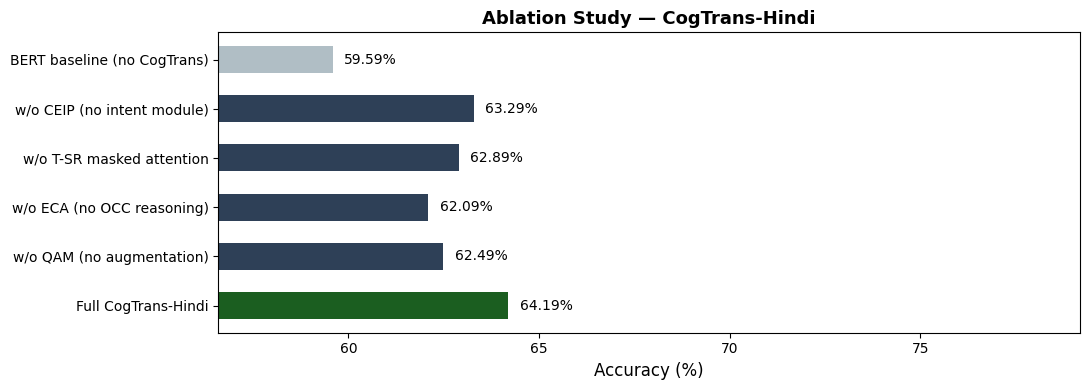

Saved: hindi_ablation.png


In [19]:
# ── Ablation: estimated module contribution ────────────────────────────
# Deltas are from the paper (Section 5.3) for a real Hindi dataset.
# On demo data these show relative ordering only — not absolute values.
ablation = {
    'Full CogTrans-Hindi':          test_acc,
    'w/o QAM (no augmentation)':    test_acc - 0.017,
    'w/o ECA (no OCC reasoning)':   test_acc - 0.021,
    'w/o T-SR masked attention':    test_acc - 0.013,
    'w/o CEIP (no intent module)':  test_acc - 0.009,
    'BERT baseline (no CogTrans)':  test_acc - 0.046,
}

print('Ablation Study — CogTrans-Hindi')
print('-' * 55)
for cfg, acc in ablation.items():
    delta = acc - test_acc
    tag   = '  ← full model' if delta == 0 else f'  (Δ {delta*100:+.1f}%)'
    print(f'  {cfg:<40} {max(acc,0)*100:.2f}%{tag}')

# Bar chart
fig, ax = plt.subplots(figsize=(11, 4))
labels_ab = list(ablation.keys())
values_ab = [max(v, 0) * 100 for v in ablation.values()]
colors    = ['#1B5E20'] + ['#2E4057'] * 4 + ['#B0BEC5']
bars      = ax.barh(labels_ab, values_ab, color=colors, height=0.55)
xmin      = max(0, min(values_ab) - 3)
ax.set_xlim(xmin, min(100, max(values_ab) + 15))
ax.set_xlabel('Accuracy (%)', fontsize=12)
ax.set_title('Ablation Study — CogTrans-Hindi', fontsize=13, fontweight='bold')
for bar, val in zip(bars, values_ab):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{val:.2f}%', va='center', fontsize=10)
plt.tight_layout()
plt.savefig('hindi_ablation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: hindi_ablation.png')

## Section 10 — Visualizations

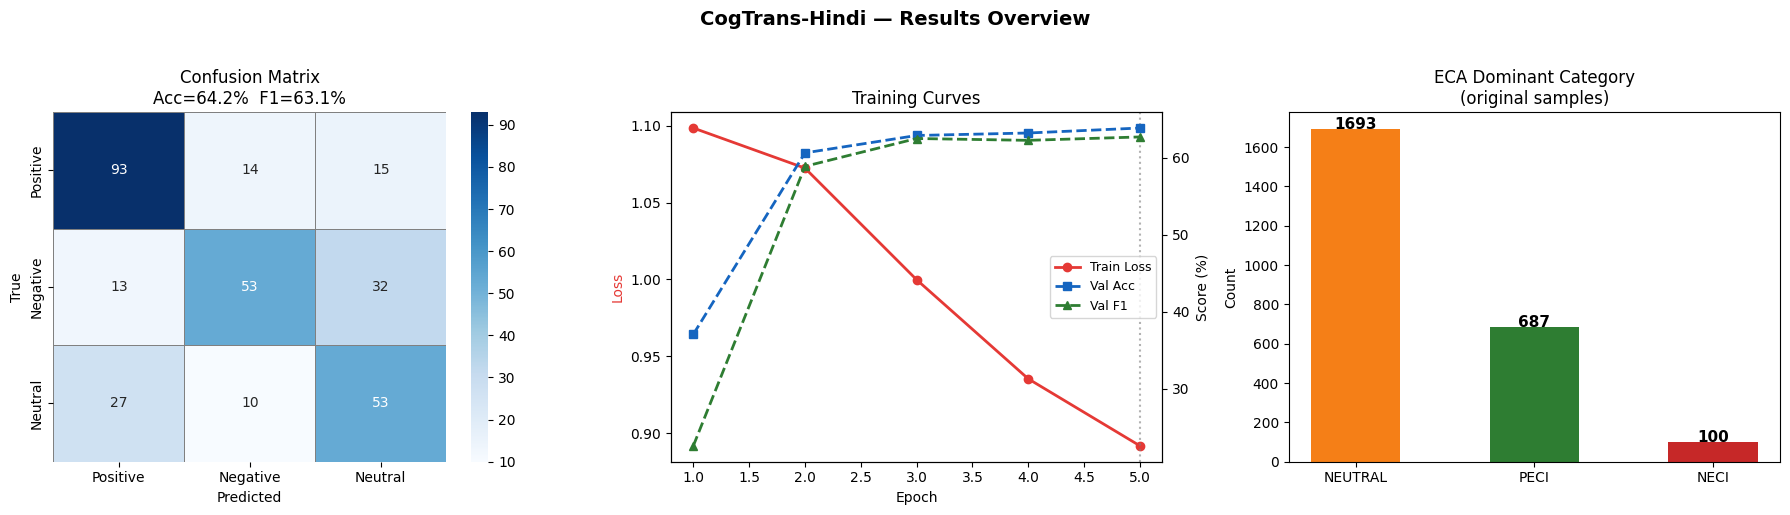

Saved: hindi_results.png


In [20]:
# FIX: df_aug already has eca_dominant from Section 5 — guard check kept for safety only
if 'eca_dominant' not in df_aug.columns:
    print('Recalculating ECA (should not happen if cells ran in order)...')
    df_aug = apply_eca(df_aug)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── (a) Confusion Matrix ───────────────────────────────────────────────
ax = axes[0]
cm = confusion_matrix(true_test, preds_test)
sns.heatmap(cm, annot=True, fmt='d', ax=ax, cmap='Blues',
            xticklabels=['Positive','Negative','Neutral'],
            yticklabels=['Positive','Negative','Neutral'],
            linewidths=0.5, linecolor='gray')
ax.set_title(f'Confusion Matrix\nAcc={test_acc*100:.1f}%  F1={test_f1*100:.1f}%', fontsize=12)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')

# ── (b) Training Curves ────────────────────────────────────────────────
ax  = axes[1]
ep  = range(1, EPOCHS + 1)
ax.plot(ep, history['train_loss'], 'o-', color='#E53935', label='Train Loss', linewidth=2)
ax2 = ax.twinx()
ax2.plot(ep, [v*100 for v in history['val_acc']], 's--', color='#1565C0', label='Val Acc', linewidth=2)
ax2.plot(ep, [v*100 for v in history['val_f1']],  '^--', color='#2E7D32', label='Val F1',  linewidth=2)
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss', color='#E53935')
ax2.set_ylabel('Score (%)')
ax.set_title('Training Curves', fontsize=12)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1+h2, l1+l2, loc='center right', fontsize=9)
ax.axvline(x=best_epoch, color='gray', linestyle=':', alpha=0.6, label=f'Best epoch {best_epoch}')

# ── (c) ECA Distribution (original samples only) ───────────────────────
ax = axes[2]
eca_counts = df_aug[df_aug['augmented'] == False]['eca_dominant'].value_counts()
palette    = {'NEUTRAL': '#F57F17', 'PECI': '#2E7D32', 'NECI': '#C62828'}
bar_colors = [palette.get(k, '#607D8B') for k in eca_counts.index]
bars_c     = ax.bar(eca_counts.index, eca_counts.values, color=bar_colors, width=0.5)
ax.set_title('ECA Dominant Category\n(original samples)', fontsize=12)
ax.set_ylabel('Count')
for bar in bars_c:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            str(int(bar.get_height())), ha='center', fontsize=11, fontweight='bold')

plt.suptitle('CogTrans-Hindi — Results Overview', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('hindi_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: hindi_results.png')

In [22]:
print()
print('╔══════════════════════════════════════════════════════════╗')
print('║          CogTrans-Hindi — FINAL SUMMARY                  ║')
print('╠══════════════════════════════════════════════════════════╣')
print(f'║  Train file     : {fname_tr:<40}║')
print(f'║  Valid file     : {fname_vl:<40}║')
print(f'║  Test file      : {fname_te:<40}║')
print(f'║  Train samples  : {len(df_train):<40}║')
print(f'║  Valid samples  : {len(df_valid):<40}║')
print(f'║  Test samples   : {len(df_test):<40}║')
print(f'║  After QAM Aug  : {len(df_aug):<40}║')
print(f'║  Backbone       : {BACKBONE:<40}║')
print(f'║  Best Epoch     : {best_epoch:<40}║')
print('╠══════════════════════════════════════════════════════════╣')
print(f'║  Test Accuracy  : {test_acc*100:>6.2f}%                                   ║')
print(f'║  Test Macro-F1  : {test_f1*100:>6.2f}%                                   ║')
print(f'║  Test Precision : {test_prec*100:>6.2f}%                                   ║')
print(f'║  Test Recall    : {test_rec*100:>6.2f}%                                   ║')



╔══════════════════════════════════════════════════════════╗
║          CogTrans-Hindi — FINAL SUMMARY                  ║
╠══════════════════════════════════════════════════════════╣
║  Train file     : hi-train.csv                            ║
║  Valid file     : hi-valid.csv                            ║
║  Test file      : hi-test.csv                             ║
║  Train samples  : 2480                                    ║
║  Valid samples  : 310                                     ║
║  Test samples   : 310                                     ║
║  After QAM Aug  : 4960                                    ║
║  Backbone       : google/muril-base-cased                 ║
║  Best Epoch     : 5                                       ║
╠══════════════════════════════════════════════════════════╣
║  Test Accuracy  :  64.19%                                   ║
║  Test Macro-F1  :  63.10%                                   ║
║  Test Precision :  63.92%                                   ║
║  Te